# Tema : Modelo LSTM
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

# Ejercicio 1. Demanda diaria de electricidad en Victoria, Australia

- Una aplicación común de estos modelos es el pronóstico de la demanda de electricidad. Tenemos la demanda de electricidad cada media hora (MWh) en Victoria, Australia, durante el periodo 2012-2014, junto con la temperatura (en grados Celsius) en Melbourne, la ciudad más grande de Victoria.
- Para este ejercicio agregamos los datos a frecuencia diaria. La demanda diaria es la suma de las demandas de cada media hora, expresada en GWh, y la temperatura diaria es la temperatura máxima del día.
- El objetivo es pronosticar la demanda de los últimos 90 días de 2014 con dos tipos de redes neuronales. La primera es la red neuronal autorregresiva `NNETAR()` del paquete `fable`, que presenta el libro [Forecasting: Principles and Practice](https://otexts.com/fpp3/nnetar.html) en la sección 12.3. La segunda es una red LSTM construida con el paquete `torch`.
- Usamos los mismos datos y el mismo periodo de prueba del notebook de Prophet, de modo que los resultados de ambos notebooks se pueden comparar.

In [1]:
# Librerias necesarias
suppressPackageStartupMessages({
  library(tidyverse)     # Manipulación de datos y gráficos
  library(tsibble)       # Estructura de datos para series de tiempo
  library(fable)         # Modelos de pronóstico (SNAIVE, NNETAR)
  library(feasts)        # Características y diagnóstico de series
  library(ggtime)        # Gráficos de series de tiempo
  library(caret)         # Escalamiento con preProcess()
  library(torch)         # Redes neuronales (LSTM)
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

## Datos

In [2]:
# datos de electricidad cada media hora
vic_elec_raw <- read_csv("../data/vic_elec.csv", show_col_types = FALSE)

elec <- vic_elec_raw |>
  pivot_wider(names_from = unique_id, values_from = y) |>
  mutate(Fecha = as_date(ds)) |>
  group_by(Fecha) |>
  summarise(
    Demand      = sum(Demand) / 1e3,   # Demanda total del día en GWh
    Temperature = max(Temperature),    # Temperatura máxima del día
    Holiday     = any(Holiday)
  ) |>
  mutate(Working_Day = as.integer(!Holiday & !wday(Fecha, week_start = 1) %in% 6:7)) |>
  as_tsibble(index = Fecha)

head(elec)

Fecha,Demand,Temperature,Holiday,Working_Day
<date>,<dbl>,<dbl>,<lgl>,<int>
2012-01-01,222.4379,32.7,TRUE,0
2012-01-02,257.9647,39.6,TRUE,0
2012-01-03,267.0986,31.8,FALSE,1
2012-01-04,222.7423,25.1,FALSE,1
2012-01-05,210.5852,21.2,FALSE,1
2012-01-06,210.2465,23.6,FALSE,1


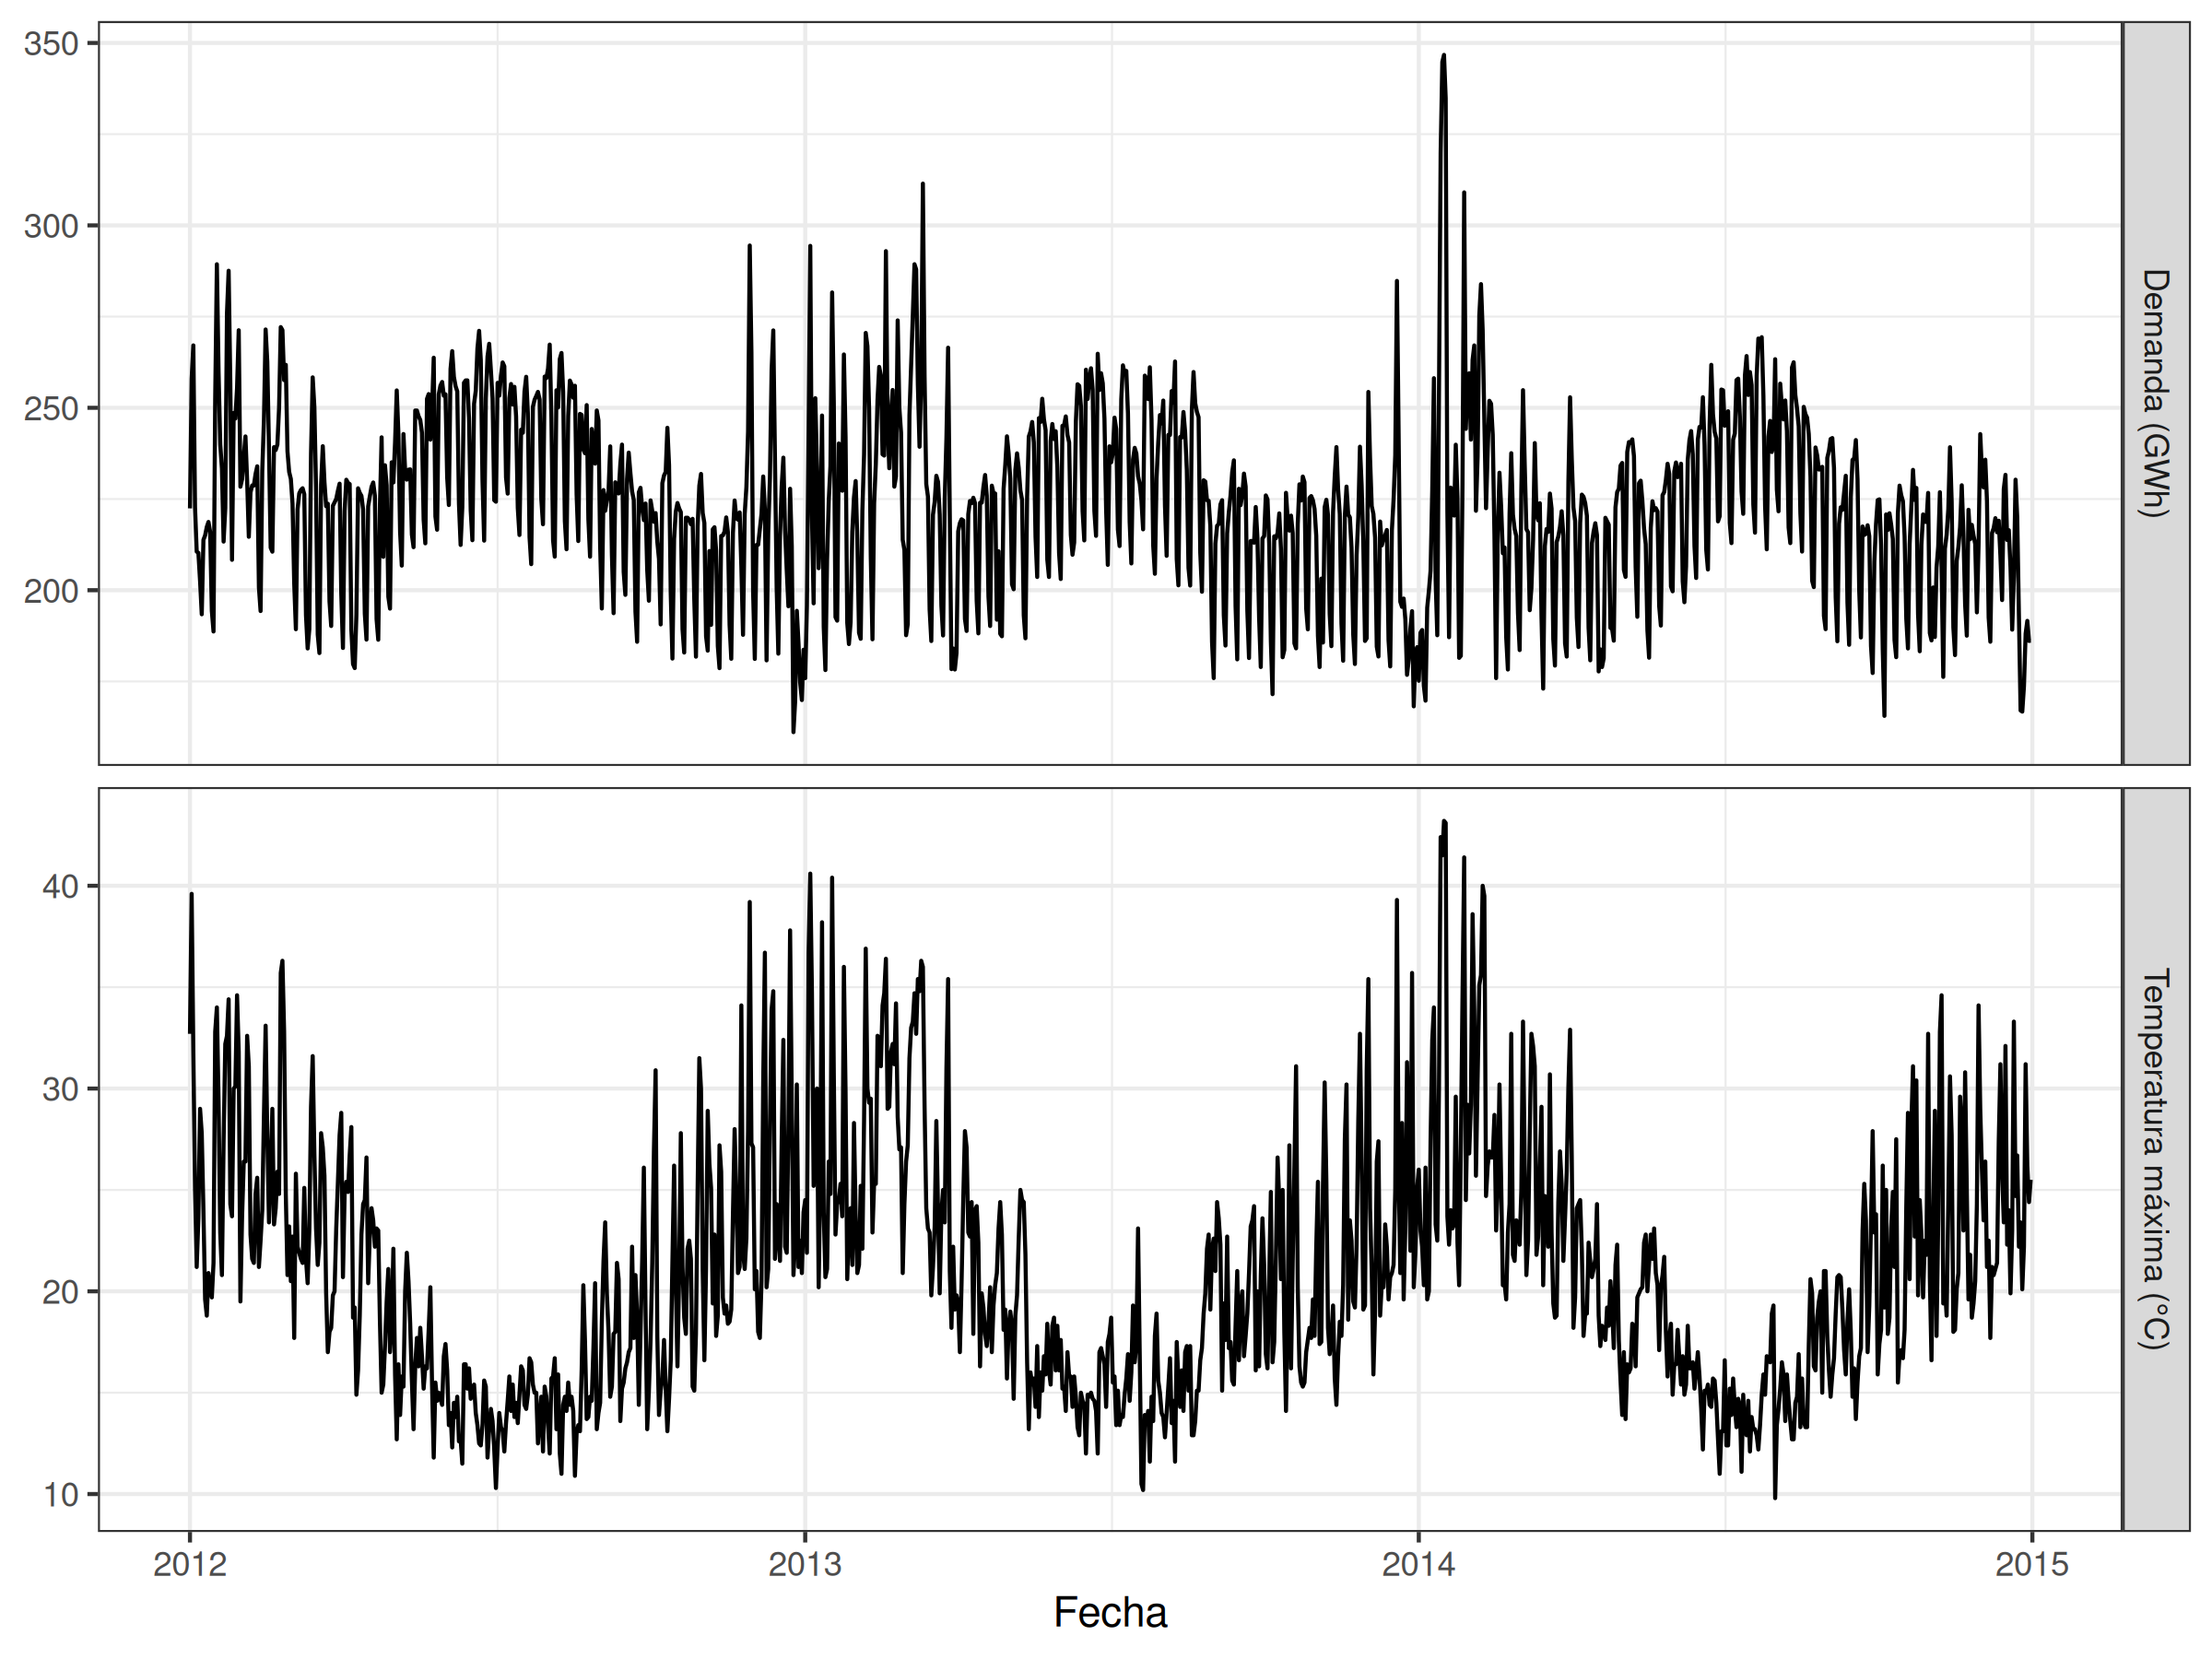

In [3]:
elec |>
  pivot_longer(c(Demand, Temperature)) |>
  mutate(name = recode(name, Demand = "Demanda (GWh)", Temperature = "Temperatura máxima (°C)")) |>
  ggplot(aes(x = Fecha, y = value)) +
  geom_line() +
  facet_grid(name ~ ., scales = "free_y") +
  labs(x = "Fecha", y = NULL)

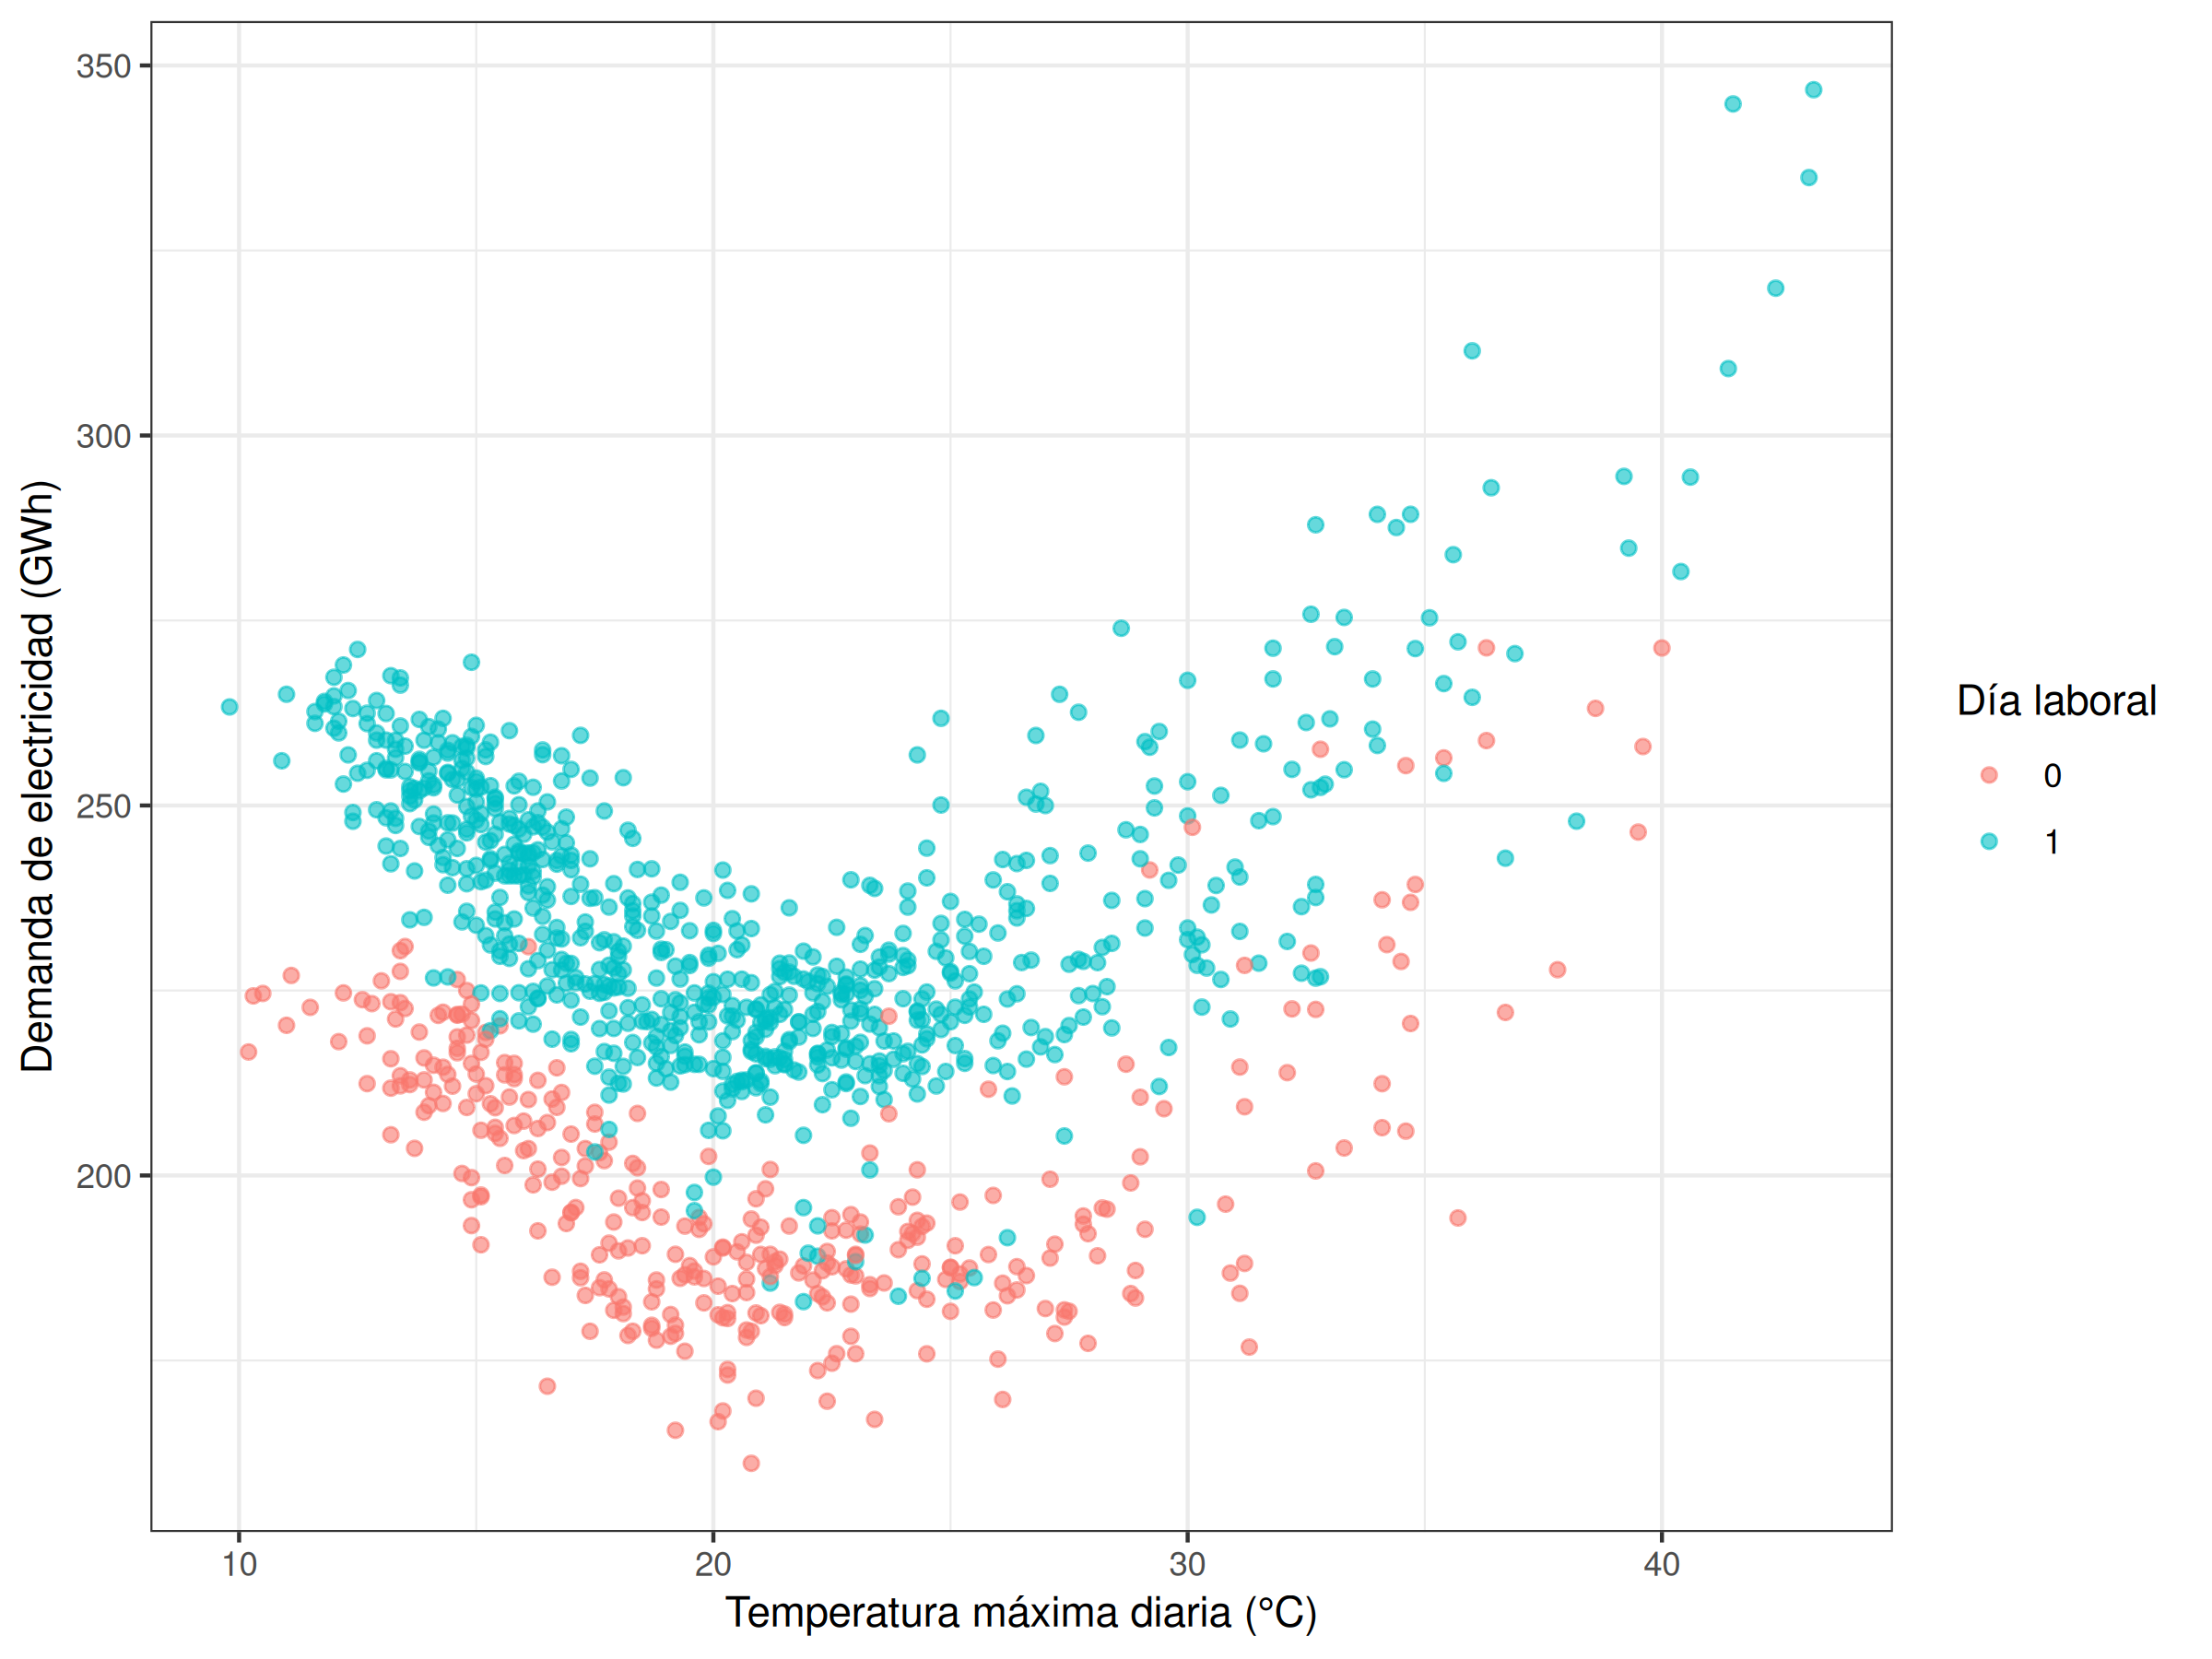

In [4]:
elec |>
  ggplot(aes(x = Temperature, y = Demand, colour = factor(Working_Day))) +
  geom_point(alpha = 0.6) +
  labs(x = "Temperatura máxima diaria (°C)",
       y = "Demanda de electricidad (GWh)",
       colour = "Día laboral")

Si se representa la demanda de electricidad en función de la temperatura, se observa una relación no lineal entre ambas. La demanda aumenta con las temperaturas bajas, por el uso de calefacción, y con las temperaturas altas, por el uso de aire acondicionado. Además, los días laborales tienen una demanda mayor que los fines de semana y festivos. Una red neuronal puede aprender esta relación no lineal sin que tengamos que especificar su forma.

## Conjuntos de entrenamiento y prueba

- Reservamos los últimos 90 días como conjunto de prueba, igual que en el notebook de Prophet. La partición respeta el orden del tiempo, de forma que ningún modelo usa información del periodo de prueba durante la estimación.

In [5]:
h <- 90   # horizonte de pronóstico en días

train <- elec |> filter(Fecha <= max(Fecha) - h)
test  <- elec |> filter(Fecha >  max(Fecha) - h)

tibble(
  Conjunto = c("Entrenamiento", "Prueba"),
  Inicio   = c(min(train$Fecha), min(test$Fecha)),
  Fin      = c(max(train$Fecha), max(test$Fecha)),
  Dias     = c(nrow(train), nrow(test))
)

Conjunto,Inicio,Fin,Dias
<chr>,<date>,<date>,<int>
Entrenamiento,2012-01-01,2014-10-02,1006
Prueba,2014-10-03,2014-12-31,90


## Modelo de referencia y red neuronal autorregresiva (NNETAR)

- Como referencia usamos el **ingenuo estacional**, que pronostica cada día con el valor observado el mismo día de la semana anterior.
- Una red neuronal autorregresiva $NNAR(p, P, k)_m$ es una red con una sola capa oculta de $k$ neuronas, que usa como entradas los últimos $p$ valores de la serie, los valores de los mismos días en las $P$ temporadas anteriores y las regresoras. Con datos diarios el periodo estacional es $m = 7$.
- `NNETAR()` elige $p$ automáticamente y estima 20 redes con pesos iniciales aleatorios. El pronóstico es el promedio de las 20 redes.
- Los pronósticos de más de un día se calculan de forma recursiva. El pronóstico de un día se usa como entrada para pronosticar el día siguiente.
- La red no tiene una fórmula para la distribución de los pronósticos, por lo que los intervalos de predicción se obtienen simulando trayectorias futuras. El argumento `times` de `forecast()` fija el número de trayectorias simuladas.
- Usamos como regresoras la temperatura, la temperatura al cuadrado y el indicador de día laboral, igual que en el notebook de Prophet. Con la temperatura observada en el periodo de prueba hacemos un **pronóstico ex post**.

In [6]:
set.seed(42)

fit <- train |>
  model(
    snaive = SNAIVE(Demand ~ lag("week")),
    nnetar = NNETAR(Demand ~ Temperature + I(Temperature^2) + Working_Day)
  )

fit

snaive,nnetar
<model>,<model>
<SNAIVE>,"<NNAR(29,1,16)[7]>"


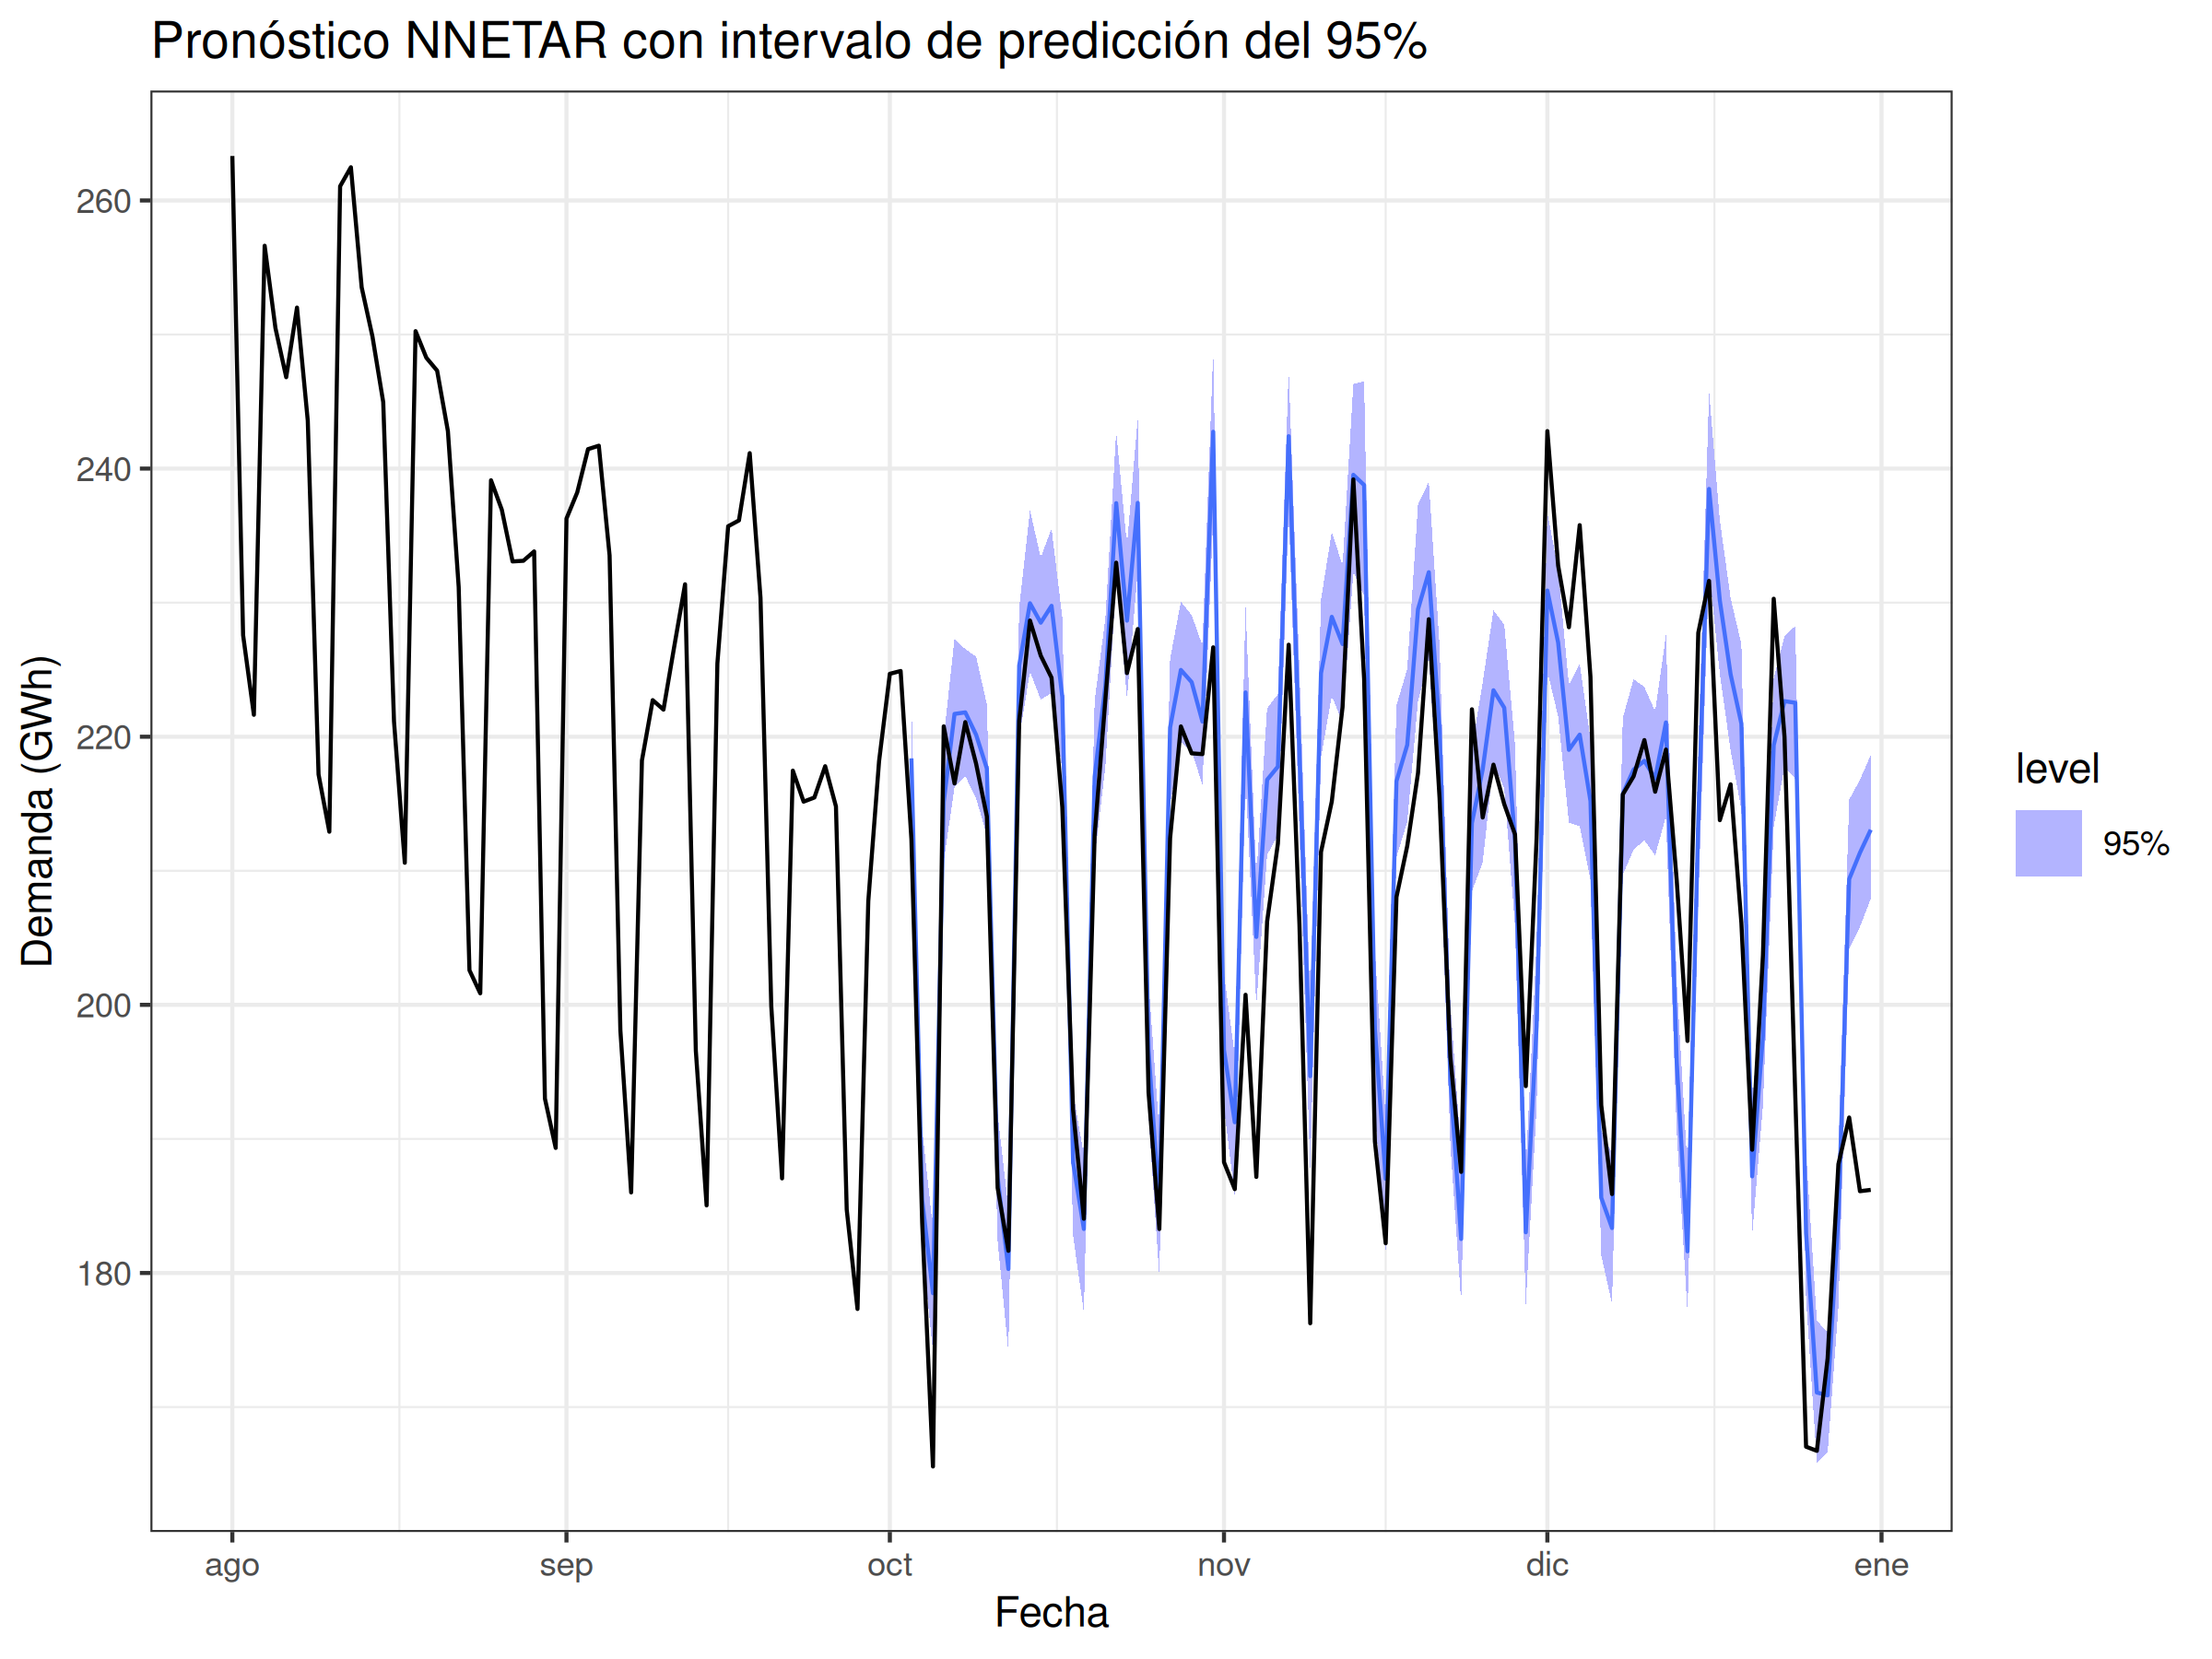

In [7]:
set.seed(42)
fc <- fit |> forecast(new_data = test, times = 100)

fc |>
  filter(.model == "nnetar") |>
  autoplot(elec |> filter(Fecha >= ymd("2014-08-01")), level = 95) +
  labs(x = "Fecha", y = "Demanda (GWh)",
       title = "Pronóstico NNETAR con intervalo de predicción del 95%")

In [8]:
accuracy(fc, elec) |>
  select(.model, RMSE, MAE, MAPE)

.model,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
nnetar,10.09663,7.828841,3.825483
snaive,15.19595,10.776437,5.343388


**Interpretación**

- `NNETAR()` eligió una red $NNAR(29,1,16)_7$. La red usa como entradas la demanda de los últimos 29 días, la demanda del mismo día de la semana anterior y las tres regresoras, y tiene 16 neuronas en la capa oculta.
- La red pronostica mucho mejor que el ingenuo estacional. Su RMSE de 10.1 GWh y su MAPE de 3.8% son parecidos a los de la regresión con errores ARIMA y de Prophet sin regresoras del notebook de Prophet, pero peores que los de Prophet con regresoras.
- El pronóstico sigue bien el patrón semanal y la caída de la demanda en Navidad, pero en varios días sobreestima los picos de demanda.
- El intervalo de predicción es angosto y varios valores observados quedan por fuera. Las trayectorias simuladas solo incluyen el error aleatorio de cada día y no la incertidumbre en los pesos de la red, por lo que estos intervalos tienden a subestimar la incertidumbre real.

## Modelo usando LSTM

### Pasos
1. Definir las variables de entrada.
2. Escalar los datos entre 0 y 1, ajustando el escalamiento solo con el conjunto de entrenamiento.
3. Convertir la serie de tiempo en secuencias. Transformamos los datos en ventanas deslizantes que sirven de entrada a la LSTM.
4. Construir y entrenar el modelo LSTM con parada temprana.
5. Pronosticar el periodo de prueba a un paso y de forma recursiva, y comparar con los demás modelos.

## Variables de entrada

- La red usa como entrada la demanda, la temperatura máxima y el indicador de día laboral de los días anteriores.
- La temperatura y el tipo de día del día que se quiere pronosticar también son muy informativos. Para incluirlos en la ventana, desplazamos un día hacia atrás esas dos variables con `lead()`. Así, la fila del día $t$ contiene la demanda de $t$ y la temperatura y el tipo de día de $t+1$, y una ventana que termina en el día $t$ tiene toda la información disponible para pronosticar la demanda de $t+1$.
- La última fila no tiene día siguiente. Esa fila nunca se usa como entrada de una ventana, solo como objetivo, por lo que se completa con ceros.

In [9]:
datos <- elec |>
  as_tibble() |>
  transmute(
    Fecha,
    Demand,
    Temperature_next = lead(Temperature, default = 0),
    Working_Day_next = lead(Working_Day, default = 0)
  )

head(datos)

Fecha,Demand,Temperature_next,Working_Day_next
<date>,<dbl>,<dbl>,<int>
2012-01-01,222.4379,39.6,0
2012-01-02,257.9647,31.8,1
2012-01-03,267.0986,25.1,1
2012-01-04,222.7423,21.2,1
2012-01-05,210.5852,23.6,1
2012-01-06,210.2465,29.0,0


## Escalamiento de los datos

$$\hat{x}_i = \frac{x_i - x_{\min}}{x_{\max} - x_{\min}}$$

Donde

| Símbolo | Descripción |
|---------|-------------|
| $x_i$ | Valor original |
| $\hat{x}_i$ | Valor normalizado $\in [0, 1]$ |
| $x_{\min}$ | Mínimo de la serie en el conjunto de entrenamiento |
| $x_{\max}$ | Máximo de la serie en el conjunto de entrenamiento |

Para recuperar la escala original se usa la **transformación inversa**

$$x_i = \hat{x}_i \cdot (x_{\max} - x_{\min}) + x_{\min}$$

El mínimo y el máximo se calculan **solo con los datos de entrenamiento**. Si se calcularan con toda la serie, el escalamiento usaría información del periodo de prueba y el error de pronóstico resultaría optimista. Por esa razón, en el periodo de prueba algunos valores escalados pueden quedar por fuera del intervalo $[0, 1]$.

En R usamos la función `preProcess()` del paquete `caret` con `method = "range"`. La función calcula el mínimo y el máximo de cada variable con los datos que recibe, y `predict()` aplica la transformación a cualquier conjunto de datos. Los valores calculados quedan guardados en `preproc$ranges`, y con ellos hacemos la transformación inversa.

In [10]:
data    <- datos |> select(-Fecha)
n_total <- nrow(data)
n_train <- n_total - h          # número de días de entrenamiento

# Ajustar el escalamiento solo con el entrenamiento
preproc <- preProcess(data[1:n_train, ], method = "range")
preproc$ranges                  # fila 1 mínimo, fila 2 máximo

# Aplicar el escalamiento a toda la serie
escalada <- predict(preproc, data) |> as.matrix()

dim(escalada)
head(round(escalada, 4))

Demand,Temperature_next,Working_Day_next
161.1045,9.8,0
346.7231,43.2,1


[1] 1096    3

Demand,Temperature_next,Working_Day_next
0.3304,0.8922,0
0.5218,0.6587,1
0.5710,0.4581,1
0.3321,0.3413,1
0.2666,0.4132,1
0.2647,0.5749,0


## Ventanas deslizantes

La serie de tiempo es

| $t_1$ | $t_2$ | $t_3$ | $t_4$ | $t_5$ | $t_6$ | $t_7$ | $t_8$ | $t_9$ | $t_{10}$ |
|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:------:|
| $y_1$ | $y_2$ | $y_3$ | $y_4$ | $y_5$ | $y_6$ | $y_7$ | $y_8$ | $y_9$ | $y_{10}$ |

Con tamaño de ventana 4 y horizonte 1 tenemos una secuencia que se desliza un paso a la vez

| Ventana (X) | | | | Objetivo (y) |
|:-----------:|:-----------:|:-----------:|:-----------:|:------------:|
| $y_1$ | $y_2$ | $y_3$ | $y_4$ | $y_5$ |
| $y_2$ | $y_3$ | $y_4$ | $y_5$ | $y_6$ |
| $y_3$ | $y_4$ | $y_5$ | $y_6$ | $y_7$ |
| $y_4$ | $y_5$ | $y_6$ | $y_7$ | $y_8$ |
| $y_5$ | $y_6$ | $y_7$ | $y_8$ | $y_9$ |
| $y_6$ | $y_7$ | $y_8$ | $y_9$ | $y_{10}$ |
| **paso 1** | **paso 2** | **paso 3** | **paso 4** | **horizonte** |

Con `window = 4`, horizonte 1 y una serie de $T = 10$ observaciones, el número de muestras es

$$n\_muestras = T - window = 10 - 4 = 6$$

y las dimensiones de los arreglos resultantes son

| Arreglo | Dimensiones | Valores |
|--------|------------|---------|
| `X` | `(n_muestras, window, n_variables)` | `(6, 4, 1)` |
| `y` | `(n_muestras)` | `(6)` |

Un tensor es una generalización de los escalares, los vectores y las matrices a cualquier número de dimensiones. En R un tensor de tres dimensiones se guarda como un `array`, y el paquete `torch` lo convierte en un tensor con `torch_tensor()`.

| | **Escalar** | **Vector** | **Matriz** | **Tensor 3D** |
|---|:---:|:---:|:---:|:---:|
| **Ejes** | 0 | 1 | 2 | 3 |
| **Dimensiones** | — | `3` | `(3, 3)` | `(n, m, p)` |
| **Índice** | — | $x_i$ | $x_{ij}$ | $x_{ijk}$ |
| **En R** | `5` | `c(1, 2, 3)` | `matrix(0, 3, 3)` | `array(0, dim = c(n, m, p))` |
| **En LSTM** | Un valor $y_t$ | Una ventana $[y_1 \dots y_w]$ | Ventanas de una variable | Ventanas de múltiples variables |

En este ejercicio usamos ventanas de 14 días, que cubren dos semanas completas, y tres variables por día.

In [11]:
# Crear secuencias de la serie
crear_secuencias <- function(datos, window) {
  n_muestras <- nrow(datos) - window
  X <- array(0, dim = c(n_muestras, window, ncol(datos)))
  y <- numeric(n_muestras)
  for (i in 1:n_muestras) {
    X[i, , ] <- datos[i:(i + window - 1), ]   # ventana de días i, ..., i + window - 1
    y[i]     <- datos[i + window, 1]          # demanda del día i + window (columna 1)
  }
  list(X = X, y = y)
}

window <- 14
secuencias <- crear_secuencias(escalada, window)

# El objetivo de la muestra i es el día i + window
dia_objetivo <- seq_along(secuencias$y) + window

dim(secuencias$X)   # (muestras, pasos de tiempo, variables)
length(secuencias$y)

[1] 1082   14    3

[1] 1082

In [12]:
# Dividir en entrenamiento y prueba según el día objetivo
es_train <- dia_objetivo <= n_train

X_train <- secuencias$X[es_train, , ]
y_train <- secuencias$y[es_train]
X_test  <- secuencias$X[!es_train, , ]

# El último 10% de las muestras de entrenamiento se usa como validación
n_val   <- floor(0.1 * nrow(X_train))
idx_fit <- 1:(nrow(X_train) - n_val)
idx_val <- (nrow(X_train) - n_val + 1):nrow(X_train)

tibble(
  Conjunto = c("Ajuste", "Validación", "Prueba"),
  Muestras = c(length(idx_fit), length(idx_val), nrow(X_test))
)

Conjunto,Muestras
<chr>,<int>
Ajuste,893
Validación,99
Prueba,90


## Construir el modelo LSTM

- En `torch` un modelo se define con `nn_module()`. La función `initialize` crea las capas y la función `forward` indica cómo pasan los datos por ellas.
- La capa LSTM tiene 100 unidades y aprende los patrones temporales de la ventana. Con `batch_first = TRUE` la primera dimensión del tensor es la muestra.
- La capa de dropout apaga al azar el 20% de las neuronas en cada paso del entrenamiento para reducir el sobreajuste.
- La capa lineal convierte el último estado oculto de la LSTM en el pronóstico de la demanda del día siguiente.

In [13]:
# Semillas para que los resultados sean reproducibles
set.seed(42)
torch_manual_seed(42)

red_lstm <- nn_module(
  initialize = function(n_variables, n_unidades = 100) {
    self$lstm    <- nn_lstm(input_size = n_variables, hidden_size = n_unidades, batch_first = TRUE)
    self$dropout <- nn_dropout(p = 0.2)
    self$salida  <- nn_linear(n_unidades, 1)
  },
  forward = function(x) {
    salida_lstm <- self$lstm(x)[[1]]                   # (muestras, pasos de tiempo, unidades)
    ultimo      <- salida_lstm[, dim(salida_lstm)[2], ] # último estado oculto de la ventana
    self$salida(self$dropout(ultimo))$squeeze(2)
  }
)

modelo <- red_lstm(n_variables = dim(X_train)[3])
modelo

An `nn_module` containing 42,101 parameters.

── Modules ─────────────────────────────────────────────────────────────────────
• lstm: <nn_lstm> #42,000 parameters
• dropout: <nn_dropout> #0 parameters
• salida: <nn_linear> #101 parameters

## Entrenamiento con parada temprana

- Una época es una pasada completa del modelo por todo el conjunto de ajuste, y el tamaño del lote es el número de muestras que el modelo procesa antes de actualizar los pesos. Usamos lotes de 32 muestras en orden de tiempo.
- En cada lote se calcula la pérdida (error cuadrático medio), se calculan los gradientes con `backward()` y el optimizador Adam actualiza los pesos con `step()`.
- Al final de cada época se calcula el error en el conjunto de ajuste y en el de validación. Con `modelo$eval()` se apaga el dropout y con `with_no_grad()` se evita calcular gradientes.
- La parada temprana detiene el entrenamiento cuando el error de validación deja de mejorar durante 15 épocas, y luego recuperamos los pesos de la mejor época.

In [14]:
a_tensor <- function(x) torch_tensor(x, dtype = torch_float())

X_fit <- a_tensor(X_train[idx_fit, , ]); y_fit <- a_tensor(y_train[idx_fit])
X_val <- a_tensor(X_train[idx_val, , ]); y_val <- a_tensor(y_train[idx_val])

optimizador <- optim_adam(modelo$parameters, lr = 0.001)
lotes       <- split(seq_along(idx_fit), ceiling(seq_along(idx_fit) / 32))

historia    <- tibble()
mejor_error <- Inf
paciencia   <- 15
sin_mejora  <- 0

for (epoca in 1:200) {
  # Entrenamiento por lotes
  modelo$train()
  for (lote in lotes) {
    optimizador$zero_grad()
    perdida <- nnf_mse_loss(modelo(X_fit[lote, , ]), y_fit[lote])
    perdida$backward()
    optimizador$step()
  }

  # Error de ajuste y de validación al final de la época
  modelo$eval()
  with_no_grad({
    pred_fit <- modelo(X_fit)
    pred_val <- modelo(X_val)
    historia <- bind_rows(historia, tibble(
      Epoca          = epoca,
      MSE_Ajuste     = nnf_mse_loss(pred_fit, y_fit)$item(),
      MSE_Validacion = nnf_mse_loss(pred_val, y_val)$item(),
      MAE_Ajuste     = nnf_l1_loss(pred_fit, y_fit)$item(),
      MAE_Validacion = nnf_l1_loss(pred_val, y_val)$item()
    ))
  })

  # Parada temprana
  error_val <- tail(historia$MSE_Validacion, 1)
  if (error_val < mejor_error) {
    mejor_error  <- error_val
    mejor_epoca  <- epoca
    mejor_estado <- lapply(modelo$state_dict(), function(w) w$clone())
    sin_mejora   <- 0
  } else {
    sin_mejora <- sin_mejora + 1
  }
  if (sin_mejora >= paciencia) break
}

# Recuperar los pesos de la mejor época
modelo$load_state_dict(mejor_estado)
modelo$eval()

cat("Épocas entrenadas:", epoca, "\n")
cat("Mejor época:", mejor_epoca, "\n")

Épocas entrenadas: 149 


Mejor época: 134 


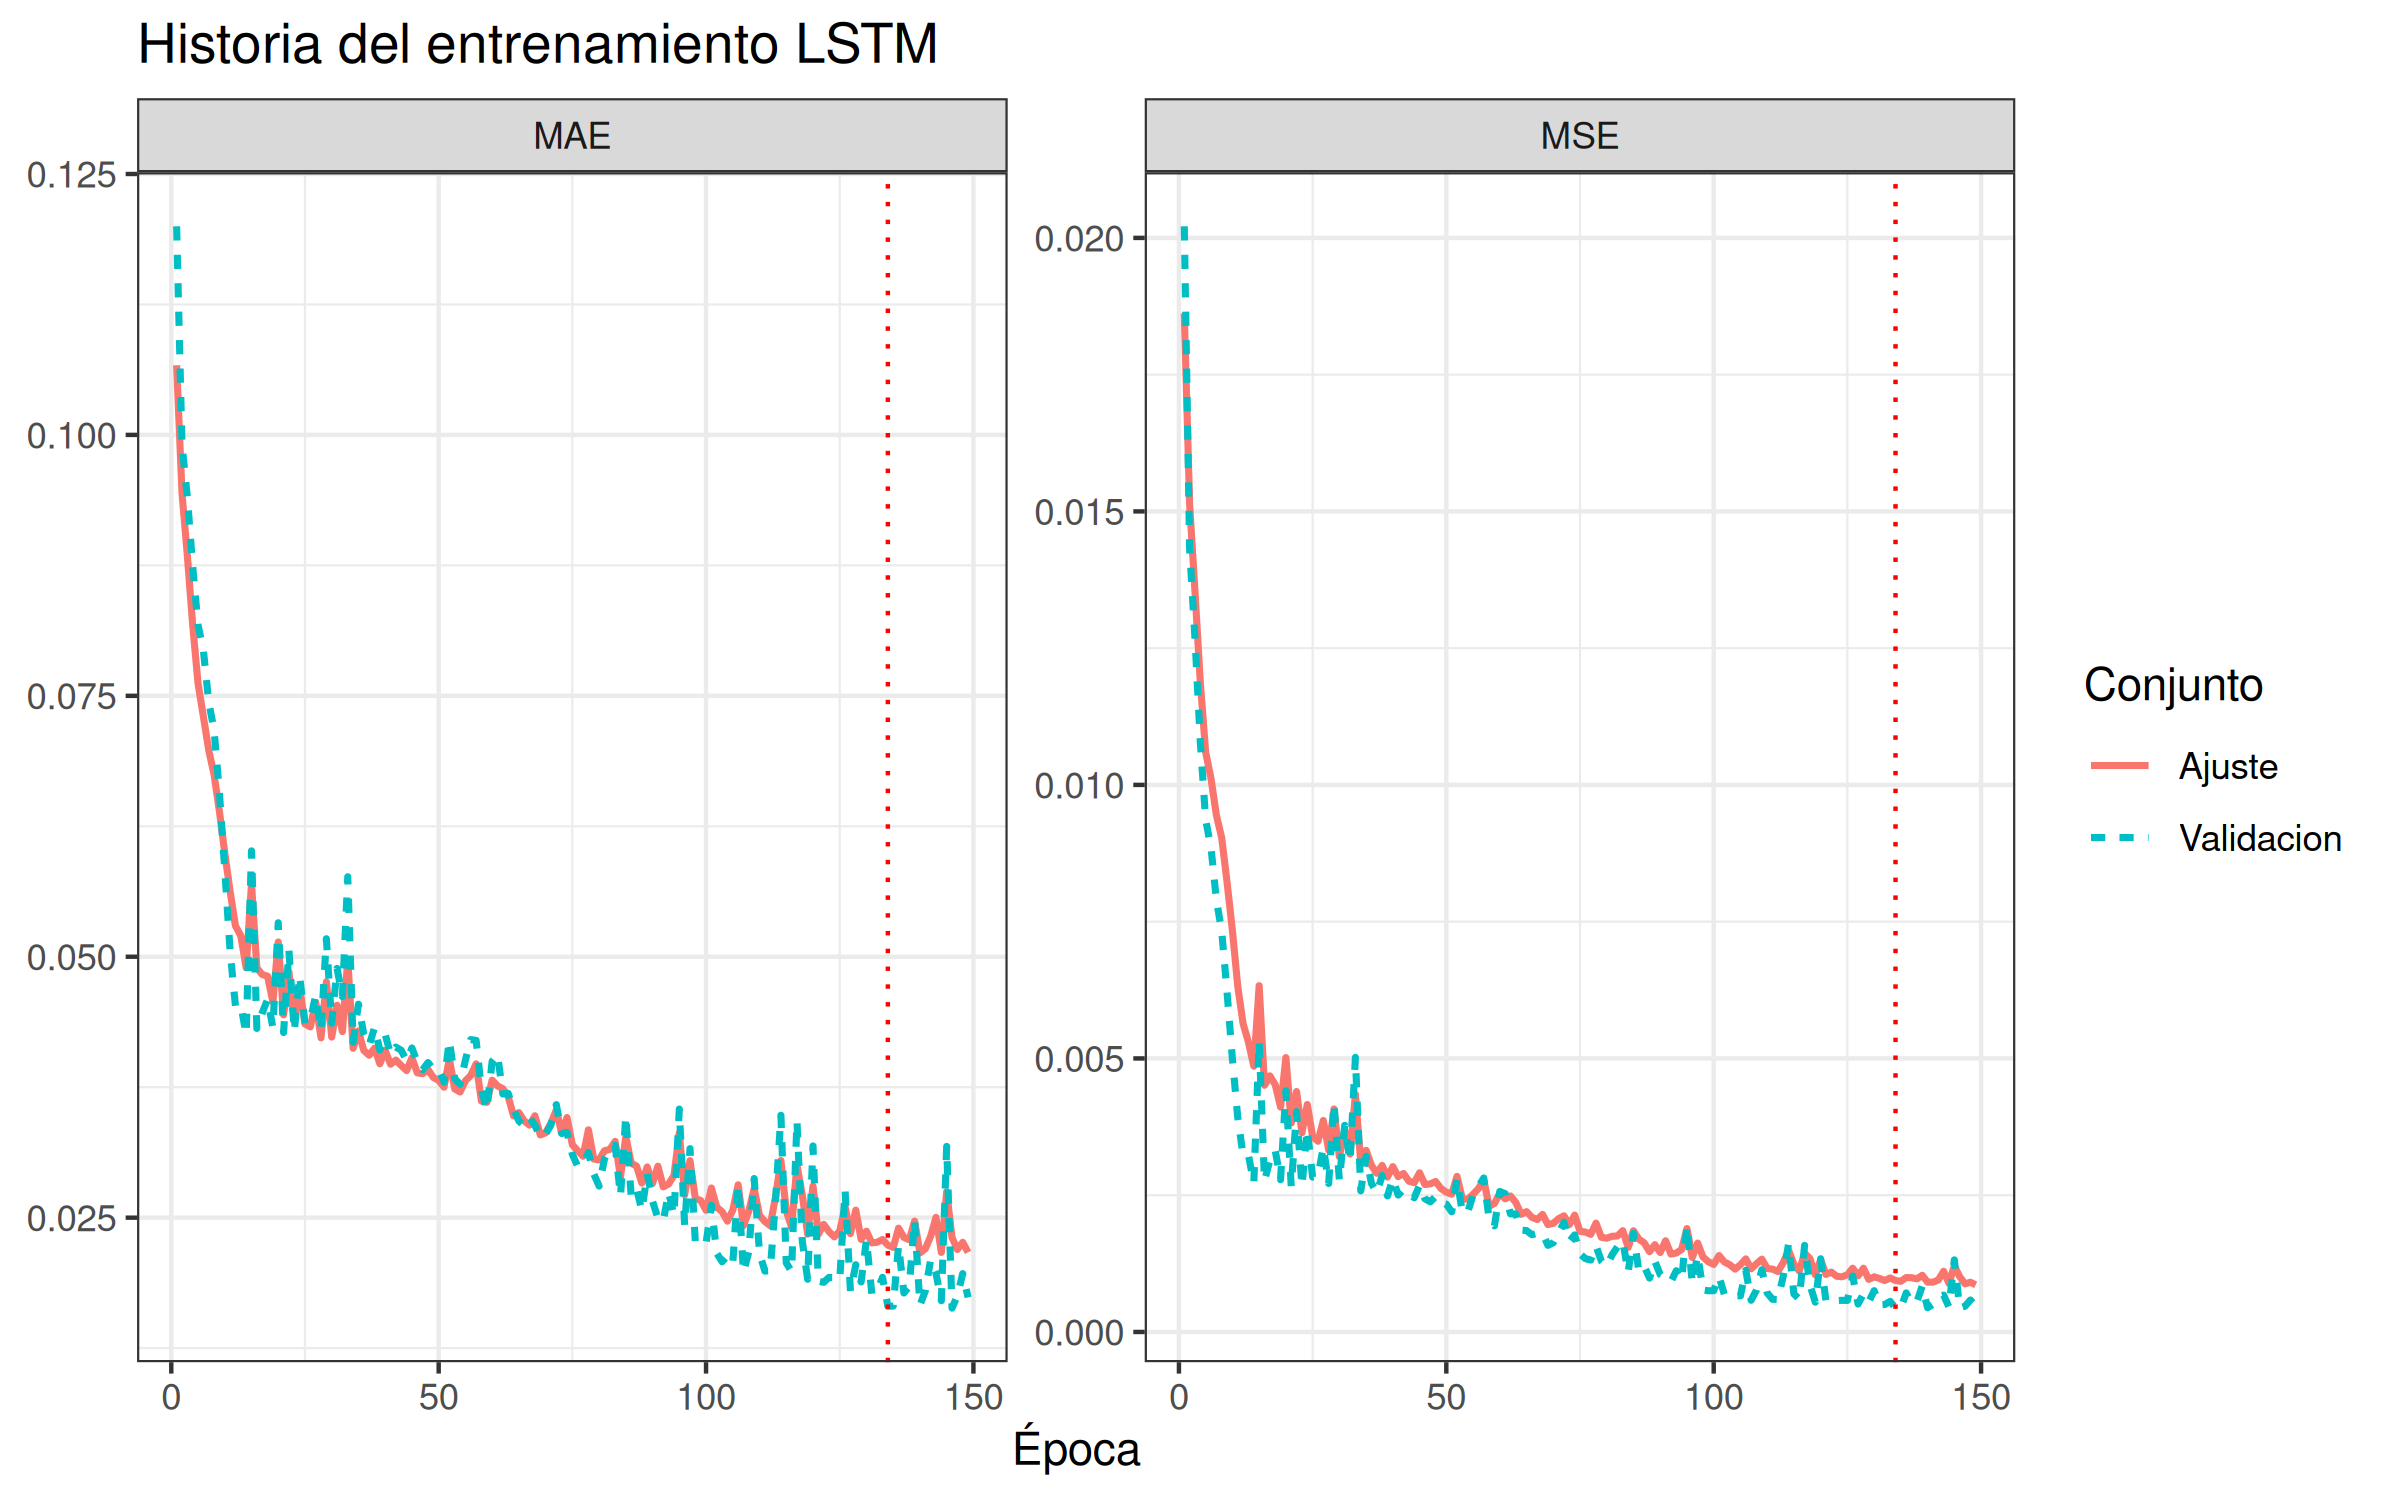

In [15]:
options(repr.plot.height = 5)
historia |>
  pivot_longer(-Epoca, names_to = c("Metrica", "Conjunto"), names_sep = "_") |>
  ggplot(aes(x = Epoca, y = value, colour = Conjunto, linetype = Conjunto)) +
  geom_line(linewidth = 0.8) +
  geom_vline(xintercept = mejor_epoca, colour = "red", linetype = "dotted") +
  facet_wrap(~ Metrica, scales = "free_y") +
  labs(x = "Época", y = NULL, title = "Historia del entrenamiento LSTM")
options(repr.plot.height = 6)

**Interpretación**

- El error de ajuste y el de validación bajan rápidamente en las primeras épocas y luego siguen bajando más despacio. Las dos curvas se mantienen cerca, por lo que no hay señales de sobreajuste.
- En las últimas épocas el error de validación es algo menor que el de ajuste. Las dos medidas se calculan sin dropout, por lo que la diferencia viene de los datos. La validación corresponde a los últimos días del entrenamiento, que caen en el invierno de 2014, cuando no hay olas de calor y la demanda es más fácil de pronosticar.
- La parada temprana detuvo el entrenamiento en la época 149 y recuperamos los pesos de la época 134, la de menor error de validación.

## Pronóstico a un paso y pronóstico recursivo

- En el **pronóstico a un paso**, cada día del periodo de prueba se pronostica con una ventana que contiene la demanda observada de los 14 días anteriores. Es el tipo de evaluación más común en los ejemplos de LSTM, pero supone que cada día conocemos la demanda real del día anterior.
- En el **pronóstico recursivo**, el modelo pronostica los 90 días desde el último día de entrenamiento. Cada pronóstico reemplaza a la demanda observada en la ventana del día siguiente, de modo que el modelo nunca ve la demanda real del periodo de prueba. Este es el mismo tipo de pronóstico que hacen `NNETAR()` y Prophet a 90 días, por lo que es la comparación justa.

In [16]:
# Transformación inversa de la demanda (columna 1 del escalamiento)
x_min <- preproc$ranges[1, "Demand"]
x_max <- preproc$ranges[2, "Demand"]
a_escala_original <- function(valores) valores * (x_max - x_min) + x_min

# Pronóstico a un paso
pred_un_paso <- with_no_grad(as.numeric(modelo(a_tensor(X_test)))) |>
  a_escala_original()

# Pronóstico recursivo
serie <- escalada
for (t in (n_train + 1):n_total) {
  ventana <- a_tensor(serie[(t - window):(t - 1), , drop = FALSE])$unsqueeze(1)  # 14 días anteriores
  serie[t, 1] <- with_no_grad(as.numeric(modelo(ventana)))  # el pronóstico reemplaza la demanda del día t
}
pred_recursivo <- a_escala_original(serie[(n_train + 1):n_total, 1])

## Evaluación de los modelos

- El MAE es el error absoluto medio, el RMSE es la raíz del error cuadrático medio y el MAPE es el error porcentual absoluto medio. Los tres se calculan en GWh sobre los 90 días de prueba.
- Reunimos en una sola tabla los pronósticos puntuales de los modelos de `fable` y de la LSTM, y calculamos las métricas para cada modelo.

In [17]:
pronosticos <- bind_rows(
  fc |>
    as_tibble() |>
    transmute(Fecha, Modelo = .model, Pronostico = .mean),
  tibble(Fecha = test$Fecha, Modelo = "lstm_un_paso",   Pronostico = pred_un_paso),
  tibble(Fecha = test$Fecha, Modelo = "lstm_recursivo", Pronostico = pred_recursivo)
) |>
  left_join(as_tibble(test) |> select(Fecha, Demand), by = "Fecha")

pronosticos |>
  group_by(Modelo) |>
  summarise(
    RMSE = sqrt(mean((Demand - Pronostico)^2)),
    MAE  = mean(abs(Demand - Pronostico)),
    MAPE = 100 * mean(abs((Demand - Pronostico) / Demand))
  ) |>
  arrange(RMSE)

Modelo,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
lstm_un_paso,7.209102,5.474592,2.671248
nnetar,10.096627,7.828841,3.825483
lstm_recursivo,10.383918,7.294460,3.622673
snaive,15.195953,10.776437,5.343388


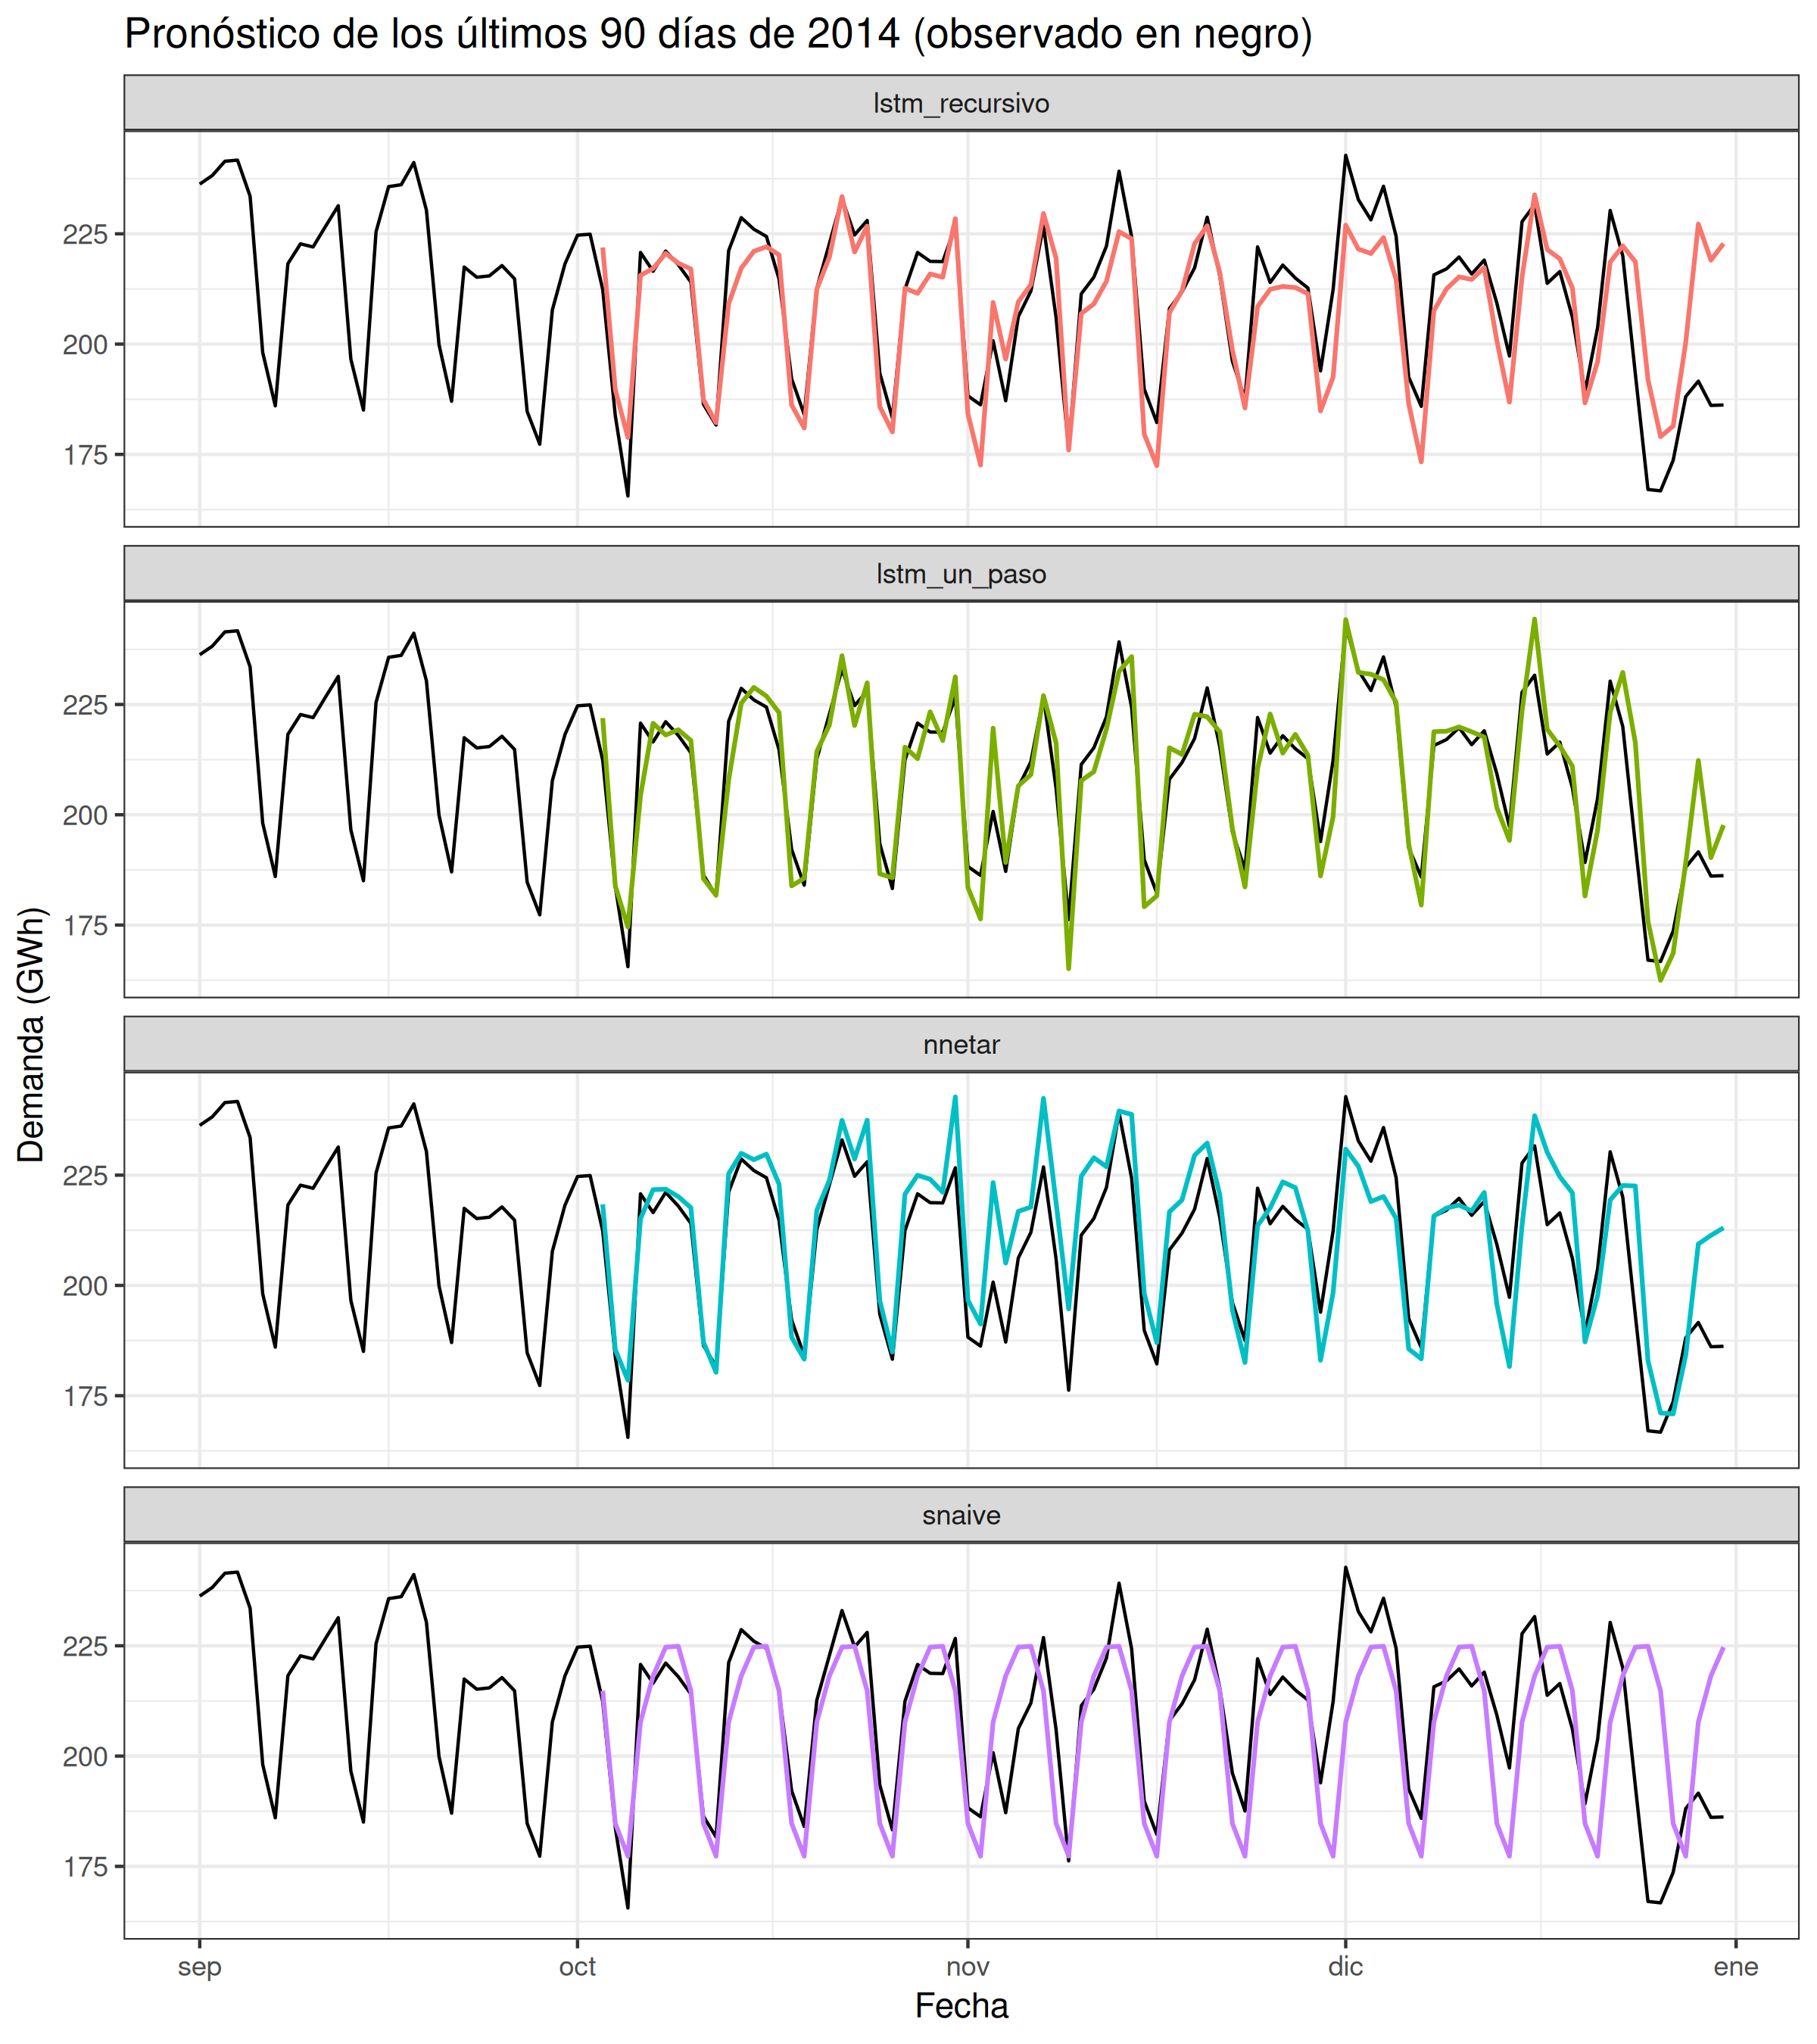

In [18]:
options(repr.plot.height = 9)
pronosticos |>
  ggplot(aes(x = Fecha)) +
  geom_line(data = as_tibble(elec) |> filter(Fecha >= ymd("2014-09-01")),
            aes(y = Demand), colour = "black") +
  geom_line(aes(y = Pronostico, colour = Modelo), linewidth = 0.7, show.legend = FALSE) +
  facet_wrap(~ Modelo, ncol = 1) +
  labs(x = "Fecha", y = "Demanda (GWh)",
       title = "Pronóstico de los últimos 90 días de 2014 (observado en negro)")
options(repr.plot.height = 6)

## Conclusiones

- El pronóstico a un paso de la LSTM tiene el menor error de la tabla, con un RMSE de 7.2 GWh. Sin embargo, en cada día de prueba usa la demanda real del día anterior, por lo que no se puede comparar con un pronóstico a 90 días.
- Entre los pronósticos a 90 días, `NNETAR()` y la LSTM recursiva tienen errores parecidos, con un RMSE cercano a 10 GWh. Los dos son mejores que el ingenuo estacional, pero peores que el modelo Prophet con regresoras del otro notebook (RMSE cercano a 8 GWh y MAPE cercano a 3%), que usa la misma información y el mismo periodo de prueba.
- En el pronóstico recursivo los errores se acumulan, porque cada pronóstico se usa como entrada del siguiente. Los errores más grandes de la LSTM recursiva aparecen entre Navidad y Año Nuevo, cuando la demanda cae por las vacaciones. La red solo vio dos periodos de fin de año en el entrenamiento, mientras que Prophet modela los festivos y la estacionalidad anual de forma explícita.
- `NNETAR()` se estima y pronostica con las mismas funciones de `fable` que los demás modelos del curso, y entrega intervalos de predicción. La LSTM requiere preparar las ventanas, escribir el ciclo de entrenamiento y elegir más hiperparámetros, y en este ejemplo no pronostica mejor.
- Este resultado coincide con lo que vimos en la presentación. Un modelo más complejo no siempre pronostica mejor, y por eso siempre se debe comparar con modelos más simples usando el mismo periodo de prueba y el mismo horizonte.
- Los pesos iniciales de la red son aleatorios. Aunque fijamos una semilla, los resultados pueden cambiar entre computadores, versiones de `torch` o entre R y Python. Por ejemplo, la LSTM recursiva del notebook de Python tiene un RMSE de 13.0 GWh.